<a href="https://colab.research.google.com/github/vsai4607/MLA0204/blob/main/program16.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Saving iris_flower_dataset (1).xlsx to iris_flower_dataset (1) (1).xlsx
Dataset:
   SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm Species
0            5.1           3.5            1.4           0.2  setosa
1            4.9           3.0            1.4           0.2  setosa
2            4.7           3.2            1.3           0.2  setosa
3            4.6           3.1            1.5           0.2  setosa
4            5.0           3.6            1.4           0.2  setosa

CLASSIFICATION ALGORITHM COMPARISON
          Algorithm  Accuracy  Precision  Recall  F1 Score
Logistic Regression     93.33      93.33   93.33     93.33
                KNN     93.33      94.44   93.33     93.27
      Decision Tree     93.33      93.33   93.33     93.33
      Random Forest     90.00      90.24   90.00     89.97
                SVM     96.67      96.97   96.67     96.66
        Naive Bayes     96.67      96.97   96.67     96.66

Best Classification Algorithm: SVM
Best Accuracy: 96.67 %


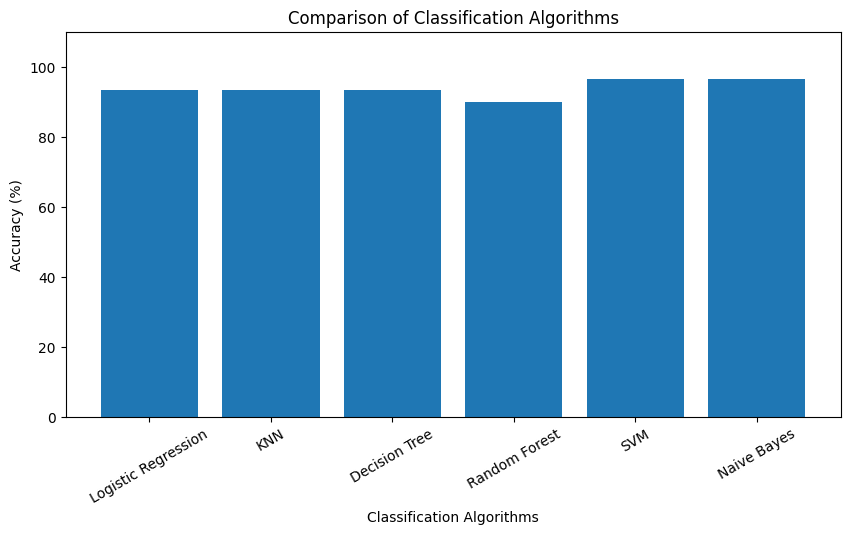

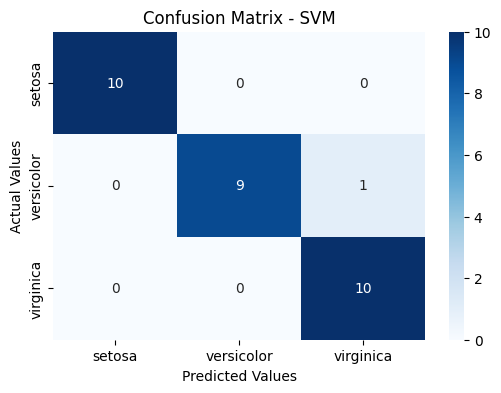


Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [3]:
# COMPARISON OF DIFFERENT CLASSIFICATION ALGORITHMS

# Step 1: Import Libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score,
    confusion_matrix, classification_report
)

# Step 2: Upload Excel Dataset
uploaded = files.upload()

# Extract the uploaded filename dynamically to prevent FileNotFoundError
uploaded_file_name = list(uploaded.keys())[0]
df = pd.read_excel(uploaded_file_name)

print("Dataset:")
print(df.head())

# Step 3: Separate Input and Output
X = df.drop('Species', axis=1)
y = df['Species']

# Step 4: Split Dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Step 5: Create Classification Models
models = {
    'Logistic Regression': make_pipeline(
        StandardScaler(), LogisticRegression(max_iter=1000)
    ),
    'KNN': make_pipeline(
        StandardScaler(), KNeighborsClassifier(n_neighbors=5)
    ),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
    'SVM': make_pipeline(
        StandardScaler(), SVC(kernel='rbf')
    ),
    'Naive Bayes': GaussianNB()
}

# Step 6: Train and Evaluate Models
results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, average='weighted', zero_division=0)
    recall = recall_score(y_test, y_pred, average='weighted', zero_division=0)
    f1 = f1_score(y_test, y_pred, average='weighted', zero_division=0)

    results.append({
        'Algorithm': name,
        'Accuracy': accuracy * 100,
        'Precision': precision * 100,
        'Recall': recall * 100,
        'F1 Score': f1 * 100
    })

# Step 7: Display Comparison Table
result_df = pd.DataFrame(results)

print("\nCLASSIFICATION ALGORITHM COMPARISON")
print(result_df.round(2).to_string(index=False))

# Step 8: Find Best Algorithm
best_model = result_df.loc[result_df['Accuracy'].idxmax()]

print("\nBest Classification Algorithm:", best_model['Algorithm'])
print("Best Accuracy:", round(best_model['Accuracy'], 2), "%")

# Step 9: Plot Accuracy Comparison
plt.figure(figsize=(10, 5))
plt.bar(result_df['Algorithm'], result_df['Accuracy'])
plt.xlabel("Classification Algorithms")
plt.ylabel("Accuracy (%)")
plt.title("Comparison of Classification Algorithms")
plt.xticks(rotation=30)
plt.ylim(0, 110)
plt.show()

# Step 10: Display Confusion Matrix for Best Model
best_name = best_model['Algorithm']
best_classifier = models[best_name]
y_pred = best_classifier.predict(X_test)
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=sorted(y.unique()),
    yticklabels=sorted(y.unique())
)
plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")
plt.title("Confusion Matrix - " + best_name)
plt.show()

# Step 11: Classification Report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Step 12: Save Comparison Results to Excel
result_df.to_excel('classification_comparison_results.xlsx', index=False)
files.download('classification_comparison_results.xlsx')